# Задание 3. Вариант 9. Набор `scene`

## 1. Подготовка
        

In [ ]:
import time
import warnings
from contextlib import redirect_stdout, redirect_stderr
from os import devnull

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, make_scorer,
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.manifold import TSNE
from imblearn.datasets import fetch_datasets

import umap
import trimap
import pacmap
from IPython.display import display

##встариваем графики прямо в ответ ячейки а не отдельно(для красоты)
%matplotlib inline
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "#fbfbfb",
    "axes.edgecolor": "#d9d9d9",
    "axes.linewidth": 0.8,
})

SEED = 42
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
# F1 редкого класса. Accuracy при дисбалансе почти всегда высокая.
F1_POS = make_scorer(f1_score, pos_label=1)

MAIN_COLOR = "#9aa8b5"   # класс −1, большинство
RARE_COLOR = "#e11d48"   # класс +1, редкий
SV_MAIN = "#1e3a8a"
SV_RARE = "#9f1239"
S_MAIN, S_RARE = 8, 18

# Четыре сочетания параметров у каждого вложения.
# Координаты считаются один раз: от меток они не зависят.
EMBED_SETTINGS = {
    "t-SNE": [
        ("perplexity=5", {"perplexity": 5}),
        ("perplexity=30", {"perplexity": 30}),
        ("perplexity=50", {"perplexity": 50}),
        ("perplexity=100", {"perplexity": 100}),
    ],
    "UMAP": [
        ("соседей 5, min_dist 0", {"n_neighbors": 5, "min_dist": 0.0}),
        ("соседей 15, min_dist 0.1", {"n_neighbors": 15, "min_dist": 0.1}),
        ("соседей 50, min_dist 0.5", {"n_neighbors": 50, "min_dist": 0.5}),
        ("соседей 30, min_dist 0.9", {"n_neighbors": 30, "min_dist": 0.9}),
    ],
    "TriMap": [
        ("inliers 5, outliers 2", {"n_inliers": 5, "n_outliers": 2}),
        ("по умолчанию", {}),
        ("inliers 20, outliers 8", {"n_inliers": 20, "n_outliers": 8}),
        ("inliers 40, outliers 15", {"n_inliers": 40, "n_outliers": 15}),
    ],
    "PaCMAP": [
        ("соседей 5", {"n_neighbors": 5}),
        ("соседей 10", {"n_neighbors": 10}),
        ("соседей 30", {"n_neighbors": 30}),
        ("MN=2, FP=1", {"n_neighbors": 10, "MN_ratio": 2.0, "FP_ratio": 1.0}),
    ],
}


##Просчитываем количество классов в датасете
def class_counts(y):
    labels, counts = np.unique(y, return_counts=True)
    return dict(zip(labels.tolist(), counts.tolist()))


##Выводим красивую табличку с полученными метриками(значениями оценок)
def metrics_frame(model, X_train, y_train, X_test, y_test):
    """Accuracy и precision/recall/F1 редкого класса +1, плюс macro."""
    rows = []
    for name, X, y in (("обучающая", X_train, y_train), ("тестовая", X_test, y_test)):
        pred = model.predict(X)
        rows.append({
            "выборка": name,
            "accuracy": accuracy_score(y, pred),
            "precision (+1)": precision_score(y, pred, pos_label=1, zero_division=0),
            "recall (+1)": recall_score(y, pred, pos_label=1, zero_division=0),
            "F1 (+1)": f1_score(y, pred, pos_label=1, zero_division=0),
            "precision macro": precision_score(y, pred, average="macro", zero_division=0),
            "recall macro": recall_score(y, pred, average="macro", zero_division=0),
            "F1 macro": f1_score(y, pred, average="macro", zero_division=0),
        })
    return pd.DataFrame(rows).set_index("выборка").round(4)


## Рисуем дважды матрицу ошибок(для обучающей и тестовой выборок), так как мы предсказываем
## только два класса -1 и +1, то матрица будет 2х2 и содержать 4 значения:
## 1)TP(true positive) - верное предсказание класса -1
## 2)FP(false positive) - ложное предсказание класса -1
## 3)TN(true negative) - верное предсказание класса +1
## 4)FN(false negative) - ложное предсказание класса +1
def show_confusion(model, X_train, y_train, X_test, y_test, title):
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.5))
    for ax, name, X, y in zip(
        axes, ("обучающая", "тестовая"), (X_train, X_test), (y_train, y_test)
    ):
        cm = confusion_matrix(y, model.predict(X), labels=[-1, 1])
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0, 1], ["−1", "+1"])
        ax.set_yticks([0, 1], ["−1", "+1"])
        ax.set_xlabel("прогноз")
        ax.set_ylabel("истинный класс")
        ax.set_title(name)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()

##Выводим красивую табличку с лучшими значениями оценок
def cv_table(search, n=12):
    df = pd.DataFrame(search.cv_results_)
    cols = [c for c in df.columns if c.startswith("param_")]
    view = df[cols + ["mean_test_score", "std_test_score"]].copy()
    view.columns = [c.replace("param_", "") for c in view.columns]
    view = view.sort_values("mean_test_score", ascending=False).head(n)
    return view.reset_index(drop=True).round(4).fillna("")

# Из строки сетки берём только параметры этого ядра: пустые ячейки чужих ядер выкидываем.(для SVM)
# Сетка — это заранее заданный список настроек модели. Поиск по сетке обучает SVM на каждом сочетании и оставляет то, у которого лучше F1. Одна строка таблицы результатов — одно такое сочетание
# Ядро задаёт, как SVM сравнивает объекты. 
# Линейное ядро строит прямую границу и настраивается только параметром C. 
# У RBF, полинома и сигмоида граница кривая, поэтому у них есть ещё gamma, степень или coef0. 
# В общей таблице столбцы у всех ядер одни и те же, но чужие для данного ядра ячейки пустые: у линейного нет степени полинома.
def params_of(row):
    """Параметры одного прогона сетки. Пустые (чужие для этого ядра) выкидываем."""
    params = {}
    for col, val in row.items():
        if not str(col).startswith("param_") or pd.isna(val):
            continue
        key = str(col).replace("param_", "")
        if key == "degree":
            val = int(val)
        elif key in {"C", "coef0"} and not isinstance(val, str):
            val = float(val)
        params[key] = val
    return params

##Наши исходные многомерные данные сжимаем методами t-SNE, UMAP, TriMap, PaCMAP(1 из них, наименование передается в параметр method)
def embed(method, X, **params):
    np.random.seed(SEED)
    started = time.time()
    with open(devnull, "w") as sink, redirect_stdout(sink), redirect_stderr(sink):
        if method == "t-SNE":
            Y = TSNE(n_components=2, random_state=SEED, n_jobs=-1, **params).fit_transform(X)
        elif method == "UMAP":
            Y = umap.UMAP(n_components=2, random_state=SEED, **params).fit_transform(X)
        elif method == "TriMap":
            Y = trimap.TRIMAP(n_dims=2, **params).fit_transform(X)
        elif method == "PaCMAP":
            model = pacmap.PaCMAP(n_components=2, random_state=SEED, **params)
            Y = model.fit_transform(np.ascontiguousarray(X, dtype=np.float32))
    return np.asarray(Y), time.time() - started

# Считает все вложения один раз: координаты от модели не зависят, дальше меняется только раскраска.
def compute_embeddings(X):
    stored = {}
    for method, settings in EMBED_SETTINGS.items():
        stored[method] = []
        for label, params in settings:
            Y, seconds = embed(method, X, **params)
            stored[method].append((label, Y, seconds))
            print(f"{method:<7} | {label:<28} | {seconds:5.1f} с")
    return stored

# Рисует одну группу точек выбранным цветом и маркером. Пустую группу пропускаем.
def _scatter_class(ax, Y, mask, color, marker, size, zorder=1):
    if not np.any(mask):
        return
    ax.scatter(
        Y[mask, 0], Y[mask, 1], s=size, c=color, marker=marker,
        alpha=0.85 if marker != "o" else 0.45,
        linewidths=0, rasterized=True, zorder=zorder,
    )

# Раскрашивает вложение: круг — класс −1, треугольник — класс +1.
# Если переданы опорные векторы, они рисуются поверх квадратом и звездой.
def draw(ax, Y, labels, sv_mask=None, y_sv=None):
    """Точки классов −1 и +1 разными цветом и маркером.

    Опорные векторы, если переданы, рисуются поверх: квадрат и звезда.
    y_sv — истинный класс опорного вектора. На картинке прогноза
    обычные точки красятся по прогнозу, опорные остаются при своём классе.
    """
    regular = np.ones(len(labels), dtype=bool) if sv_mask is None else ~sv_mask
    _scatter_class(ax, Y, regular & (labels == -1), MAIN_COLOR, "o", S_MAIN)
    _scatter_class(ax, Y, regular & (labels == 1), RARE_COLOR, "^", S_RARE, zorder=2)
    if sv_mask is not None:
        color_by = labels if y_sv is None else y_sv
        ax.scatter(
            Y[sv_mask & (color_by == -1), 0], Y[sv_mask & (color_by == -1), 1],
            s=S_RARE + 8, c=SV_MAIN, marker="s", alpha=0.9,
            linewidths=0.3, edgecolors="white", zorder=3, rasterized=True,
        )
        ax.scatter(
            Y[sv_mask & (color_by == 1), 0], Y[sv_mask & (color_by == 1), 1],
            s=S_RARE + 20, c=SV_RARE, marker="*", alpha=0.95,
            linewidths=0.3, edgecolors="white", zorder=4, rasterized=True,
        )
    ax.set_xticks([])
    ax.set_yticks([])

# Для одной модели рисует готовые вложения: верхний ряд — истинные метки, нижний — прогноз.
# support=True добавляет опорные векторы, это нужно только SVM.
def plot_model_embeddings(model, title, support=False):
    y_pred = model.predict(X_vis)
    sv_mask = None
    if support:
        sv_mask = np.zeros(len(X_vis), dtype=bool)
        sv_mask[model.support_] = True
    handles = [
        Line2D([], [], marker="o", linestyle="", color=MAIN_COLOR, markersize=7, label="класс −1"),
        Line2D([], [], marker="^", linestyle="", color=RARE_COLOR, markersize=7, label="класс +1"),
    ]
    if support:
        handles += [
            Line2D([], [], marker="s", linestyle="", color=SV_MAIN, markersize=7, label="опорный −1"),
            Line2D([], [], marker="*", linestyle="", color=SV_RARE, markersize=10, label="опорный +1"),
        ]
    for method, items in EMBEDDINGS.items():
        fig, axes = plt.subplots(2, 4, figsize=(15.2, 7.4))
        for j, (label, Y, seconds) in enumerate(items):
            draw(axes[0, j], Y, y_vis, sv_mask, y_sv=y_vis)
            draw(axes[1, j], Y, y_pred, sv_mask, y_sv=y_vis)
            axes[0, j].set_title(f"{label}\n{seconds:.0f} с")
        axes[0, 0].set_ylabel("истинные метки")
        axes[1, 0].set_ylabel("прогноз модели")
        fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
        fig.suptitle(f"{title}: {method}", fontsize=13, fontweight="bold")
        fig.tight_layout(rect=(0, 0.06, 1, 0.94))
        plt.show()

##Рисуем дерево для random forest(нужно по требованиям)
def describe_tree(estimator, feature_names, title):
    tree = estimator.tree_
    print(title)
    print(f"узлов {tree.node_count}, глубина {tree.max_depth}, листьев {tree.n_leaves}")
    feature = int(tree.feature[0])
    print(
        f"корень: {feature_names[feature]} ≤ {tree.threshold[0]:.3f}. "
        "Влево идут объекты с признаком не больше порога, вправо — остальные."
    )
    counts = np.ravel(tree.value[0])
    print(
        f"в корне объектов {int(tree.n_node_samples[0])}, "
        f"взвешенные массы классов −1 и +1: {np.round(counts, 1).tolist()}"
    )
    leaves = np.flatnonzero(tree.children_left == -1)
    # Лист с самой уверенной долей редкого класса и один лист большинства.
    masses = np.vstack([np.ravel(tree.value[i]) for i in leaves])
    share = masses[:, 1] / np.maximum(masses.sum(1), 1e-12)
    for name, leaf in (("лист с наибольшей долей +1", leaves[int(np.argmax(share))]),
                       ("лист с наибольшей долей −1", leaves[int(np.argmin(share))])):
        mass = np.ravel(tree.value[leaf])
        pred = estimator.classes_[int(np.argmax(mass))]
        print(
            f"{name}: объектов {int(tree.n_node_samples[leaf])}, "
            f"массы {np.round(mass, 1).tolist()}, предсказанный класс {int(pred)}"
        )
    print()

## Данные

        

Рабочая выборка: 2407 объектов, 294 признаков
Класс −1: 2230, класс +1: 177
Отношение −1 к +1: 12.6 : 1


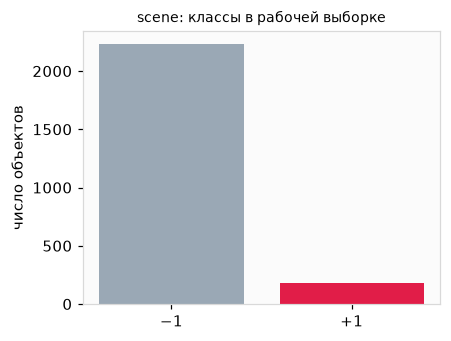

Обучающая: 1684, из них +1: 124
Тестовая:  723, из них +1: 53


In [ ]:
##Загружаем данные, выводим количество записей, кол-во классов (-1 и +1) и их отношение друг к другу 
# выводим картинку с распределением классов
# Так же делим выборку на тестовую и обучающую, баланс классов в обеих выборках сохраняем
DATASET_TITLE = "scene"
loaded = fetch_datasets(filter_data=("scene",))["scene"]
X = np.asarray(loaded.data, dtype=float)
y = np.asarray(loaded.target, dtype=int)
        

labels, counts = np.unique(y, return_counts=True)
print(f"Рабочая выборка: {X.shape[0]} объектов, {X.shape[1]} признаков")
print(f"Класс −1: {counts[labels == -1][0]}, класс +1: {counts[labels == 1][0]}")
print(f"Отношение −1 к +1: {counts.max() / counts.min():.1f} : 1")

fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.bar(["−1", "+1"], [counts[labels == -1][0], counts[labels == 1][0]], color=[MAIN_COLOR, RARE_COLOR])
ax.set_ylabel("число объектов")
ax.set_title(f"{DATASET_TITLE}: классы в рабочей выборке")
fig.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y,
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Картинки строим по всем объектам рабочей выборки.
# Обучающие идут первыми, чтобы индексы support_ SVM попали в этот же массив.
X_vis = np.vstack([X_train_s, X_test_s])
y_vis = np.concatenate([y_train, y_test])
S_MAIN = 6 if len(y_vis) > 5000 else 10
S_RARE = 16 if len(y_vis) > 5000 else 22

print(f"Обучающая: {X_train_s.shape[0]}, из них +1: {int((y_train == 1).sum())}")
print(f"Тестовая:  {X_test_s.shape[0]}, из них +1: {int((y_test == 1).sum())}")

In [ ]:
##Один раз просчитываем все снижения размерности, чтобы в дальнейшем рисовать картинки сразу
print("Вложения рабочей выборки. Метки на координаты не влияют, поэтому считаем один раз.")
EMBEDDINGS = compute_embeddings(X_vis)

Вложения рабочей выборки. Метки на координаты не влияют, поэтому считаем один раз.


t-SNE   | perplexity=5                 |   6.0 с


t-SNE   | perplexity=30                |   9.0 с


t-SNE   | perplexity=50                |  10.5 с


t-SNE   | perplexity=100               |  11.1 с


...

TriMap  | inliers 40, outliers 15      |  19.0 с


PaCMAP  | соседей 5                    |   1.4 с


PaCMAP  | соседей 10                   |   1.7 с


PaCMAP  | соседей 30                   |   3.2 с


PaCMAP  | MN=2, FP=1                   |   2.2 с


## Часть A. SVM
        

In [ ]:
##Запускаем два разных SVM и выводим таблицу с результатами
##Первая модель без весов классов, вторая с весами классов, это означает, 
# что в первом случае модель при ошибке в редком классе(+1) будет получать штраф 
# такой же как и за ошибку в популярном классе (-1) во втором случае штраф за ошибку в редком классе(+1) будет выше
rows = []
for name, weight in (("без весов классов", None), ("class_weight='balanced'", "balanced")):
    clf = SVC(kernel="rbf", C=1, gamma="scale", class_weight=weight,
              random_state=SEED, cache_size=1000)
    clf.fit(X_train_s, y_train)
    pred = clf.predict(X_test_s)
    rows.append({
        "модель": name,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision (+1)": round(precision_score(y_test, pred, pos_label=1, zero_division=0), 4),
        "recall (+1)": round(recall_score(y_test, pred, pos_label=1, zero_division=0), 4),
        "F1 (+1)": round(f1_score(y_test, pred, pos_label=1, zero_division=0), 4),
        "опорных векторов": int(clf.n_support_.sum()),
    })
display(pd.DataFrame(rows).set_index("модель"))

,accuracy,precision (+1),recall (+1),F1 (+1),опорных векторов
модель,,,,,
без весов классов,0.9281,1.0000,0.0189,0.0370,715
class_weight='balanced',0.8700,0.2267,0.3208,0.2656,939


In [ ]:
## Перебираем все настройки SVM и выбираем лучшую модель
svm_grid = [
    {"kernel": ["linear"], "C": [0.01, 0.1, 1, 10, 100]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]},
    {"kernel": ["poly"], "C": [0.1, 1, 10], "degree": [2, 3], "gamma": ["scale", 0.1], "coef0": [1.0]},
    {"kernel": ["sigmoid"], "C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1], "coef0": [0.0, 1.0]},
]
svm_search = GridSearchCV(
    SVC(class_weight="balanced", cache_size=1000, random_state=SEED),
    svm_grid, scoring=F1_POS, cv=CV, n_jobs=-1, refit=True,
)
started = time.time()
svm_search.fit(X_train_s, y_train)
svm = svm_search.best_estimator_
print(f"Сочетаний в сетке: {len(svm_search.cv_results_['params'])}, время {time.time() - started:.1f} с")
print("Лучшие параметры по F1 на кросс-валидации:", svm_search.best_params_)
print(f"F1 на кросс-валидации: {svm_search.best_score_:.4f}")
print("Лучшие 12 сочетаний:")
display(cv_table(svm_search, 12))

Сочетаний в сетке: 51, время 21.8 с
Лучшие параметры по F1 на кросс-валидации: {'C': 0.1, 'coef0': 1.0, 'degree': 3, 'gamma': 'scale', 'kernel': 'poly'}
F1 на кросс-валидации: 0.3176
Лучшие 12 сочетаний:


,C,kernel,gamma,coef0,degree,mean_test_score,std_test_score
0,0.10,poly,scale,1.0,3.0,0.3176,0.0427
1,0.10,poly,scale,1.0,2.0,0.2950,0.0298
2,1.00,rbf,scale,,,0.2865,0.0389
3,0.10,rbf,scale,,,0.2763,0.0366
4,0.10,sigmoid,scale,0.0,,0.2652,0.0164
5,0.01,linear,,,,0.2540,0.0193
6,1.00,poly,scale,1.0,2.0,0.2456,0.0537
7,0.10,rbf,0.01,,,0.2338,0.0645
8,0.10,sigmoid,scale,1.0,,0.2319,0.0178
9,1.00,sigmoid,scale,0.0,,0.2243,0.0201


Лучшая модель сетки заново учится на всей обучающей выборке. Тест в выборе не участвует.
Ниже для каждого ядра оставлены его лучшие параметры, и по ним отдельно посчитаны опорные векторы.
        

,параметры,"F1, кросс-валидация","F1, тест",опорных −1,опорных +1,опорных всего,доля обучающей
ядро,,,,,,,
poly,"C=0.1, gamma=scale, coef0=1.0, degree=3",0.3176,0.2811,884,109,993,0.5897
rbf,"C=1.0, gamma=scale",0.2865,0.2656,820,119,939,0.5576
sigmoid,"C=0.1, gamma=scale, coef0=0.0",0.2652,0.2748,1126,93,1219,0.7239
linear,C=0.01,0.2540,0.2149,759,93,852,0.5059


Выбранный SVM (poly): опорных векторов 993 из 1684 обучающих (59.0%). Класс −1: 884, класс +1: 109.
Качество выбранного SVM:


,accuracy,precision (+1),recall (+1),F1 (+1),precision macro,recall macro,F1 macro
выборка,,,,,,,
обучающая,0.902,0.4255,0.9435,0.5865,0.7102,0.9211,0.7654
тестовая,0.816,0.1970,0.4906,0.2811,0.5756,0.6662,0.5878


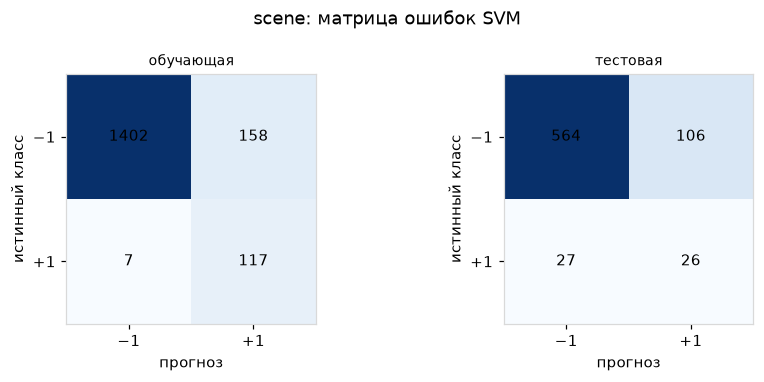

In [ ]:
## Сравниваем 4 ядра SVM между собой и выводим выбранную, для каждого ядра берется лучшее сочетаение параметров 
# и происходит повторное обучение на обучающей выборке, затем выводится таблица с результатами и матрица ошибок 
# для тестовой и обучающей выборки
kernel_rows = []
cv_results = pd.DataFrame(svm_search.cv_results_)
for kernel, part in cv_results.groupby("param_kernel"):
    best_row = part.loc[part["mean_test_score"].idxmax()]
    params = params_of(best_row)
    clf = SVC(class_weight="balanced", cache_size=1000, random_state=SEED, **params)
    clf.fit(X_train_s, y_train)
    pred = clf.predict(X_test_s)
    by_class = dict(zip(clf.classes_.tolist(), clf.n_support_.tolist()))
    kernel_rows.append({
        "ядро": kernel,
        "параметры": ", ".join(f"{k}={v}" for k, v in params.items() if k != "kernel"),
        "F1, кросс-валидация": best_row["mean_test_score"],
        "F1, тест": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "опорных −1": by_class.get(-1, 0),
        "опорных +1": by_class.get(1, 0),
        "опорных всего": int(clf.n_support_.sum()),
        "доля обучающей": clf.n_support_.sum() / len(y_train),
    })
svm_kernels = pd.DataFrame(kernel_rows).set_index("ядро")
svm_kernels = svm_kernels.sort_values("F1, кросс-валидация", ascending=False)
display(svm_kernels.round(4))

by_class = dict(zip(svm.classes_.tolist(), svm.n_support_.tolist()))
print(
    f"Выбранный SVM ({svm.kernel}): опорных векторов {int(svm.n_support_.sum())} "
    f"из {len(y_train)} обучающих ({svm.n_support_.sum() / len(y_train):.1%}). "
    f"Класс −1: {by_class.get(-1, 0)}, класс +1: {by_class.get(1, 0)}."
)
print("Качество выбранного SVM:")
display(metrics_frame(svm, X_train_s, y_train, X_test_s, y_test))
show_confusion(svm, X_train_s, y_train, X_test_s, y_test, f"{DATASET_TITLE}: матрица ошибок SVM")

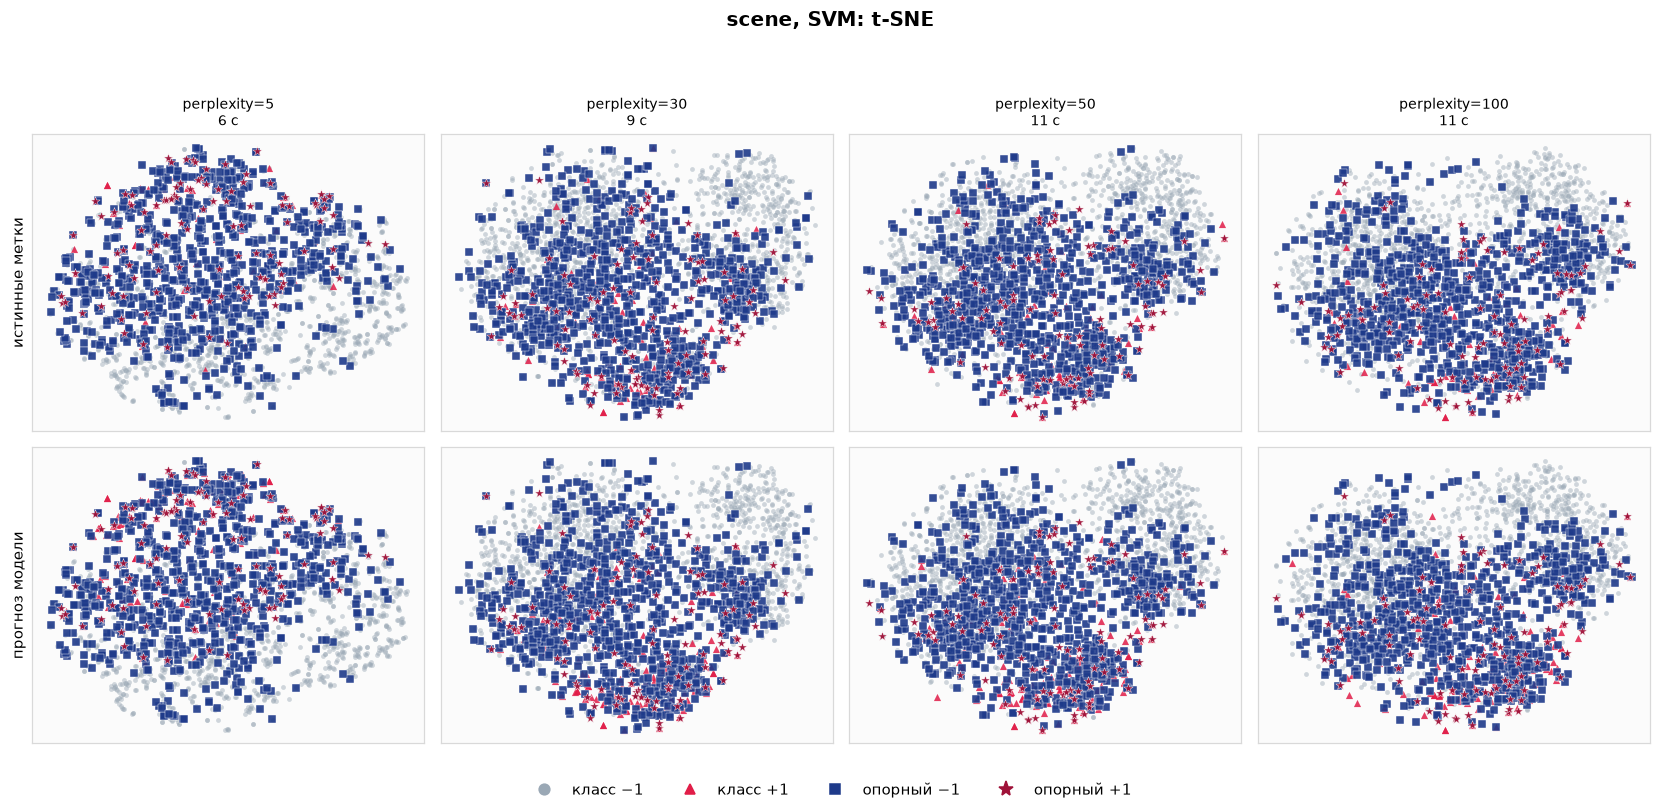

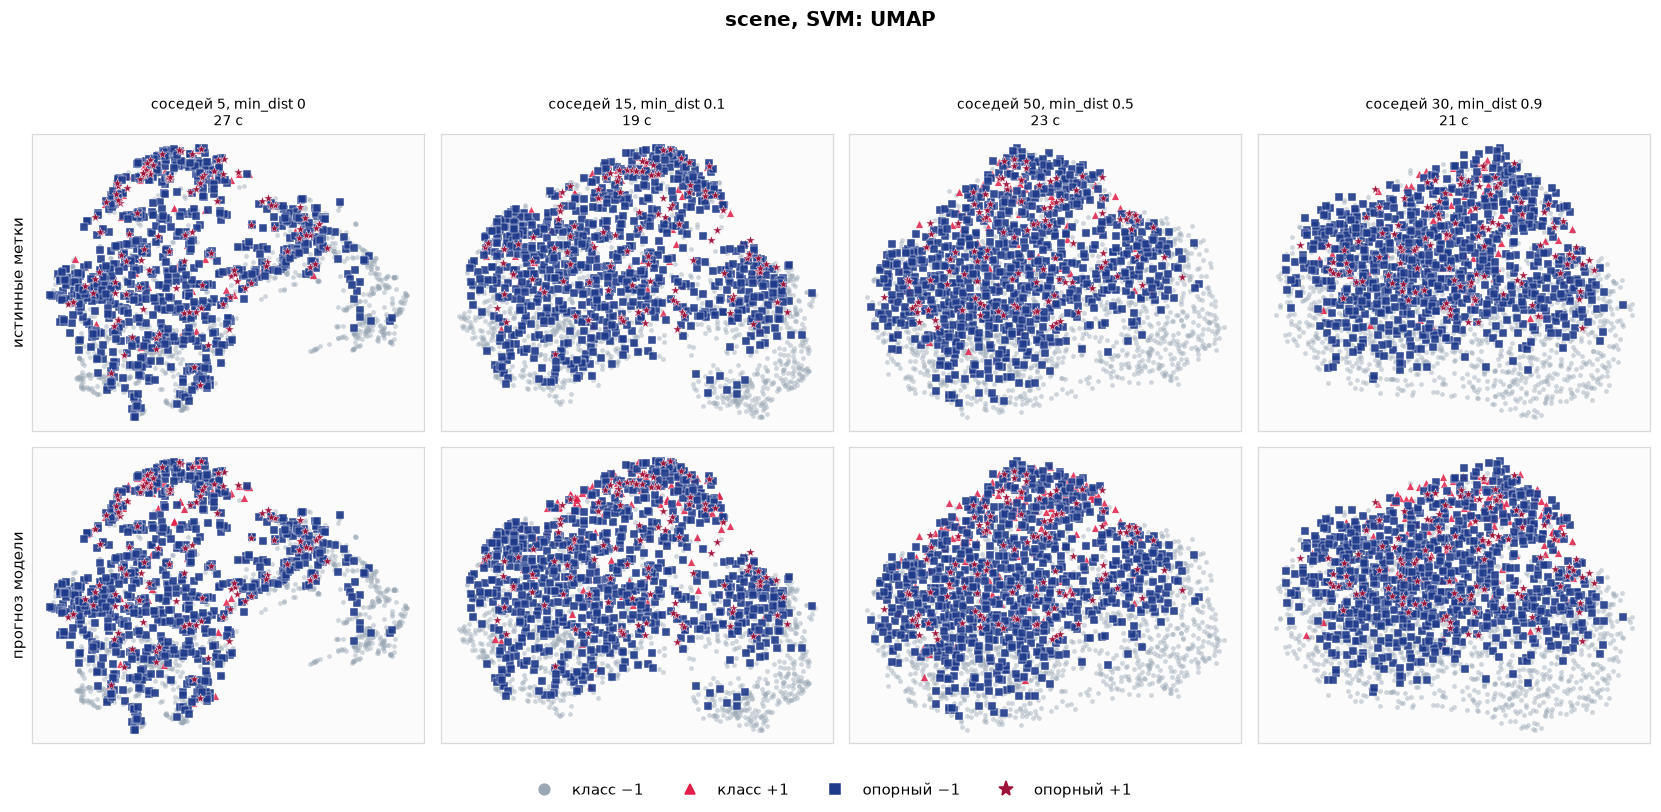

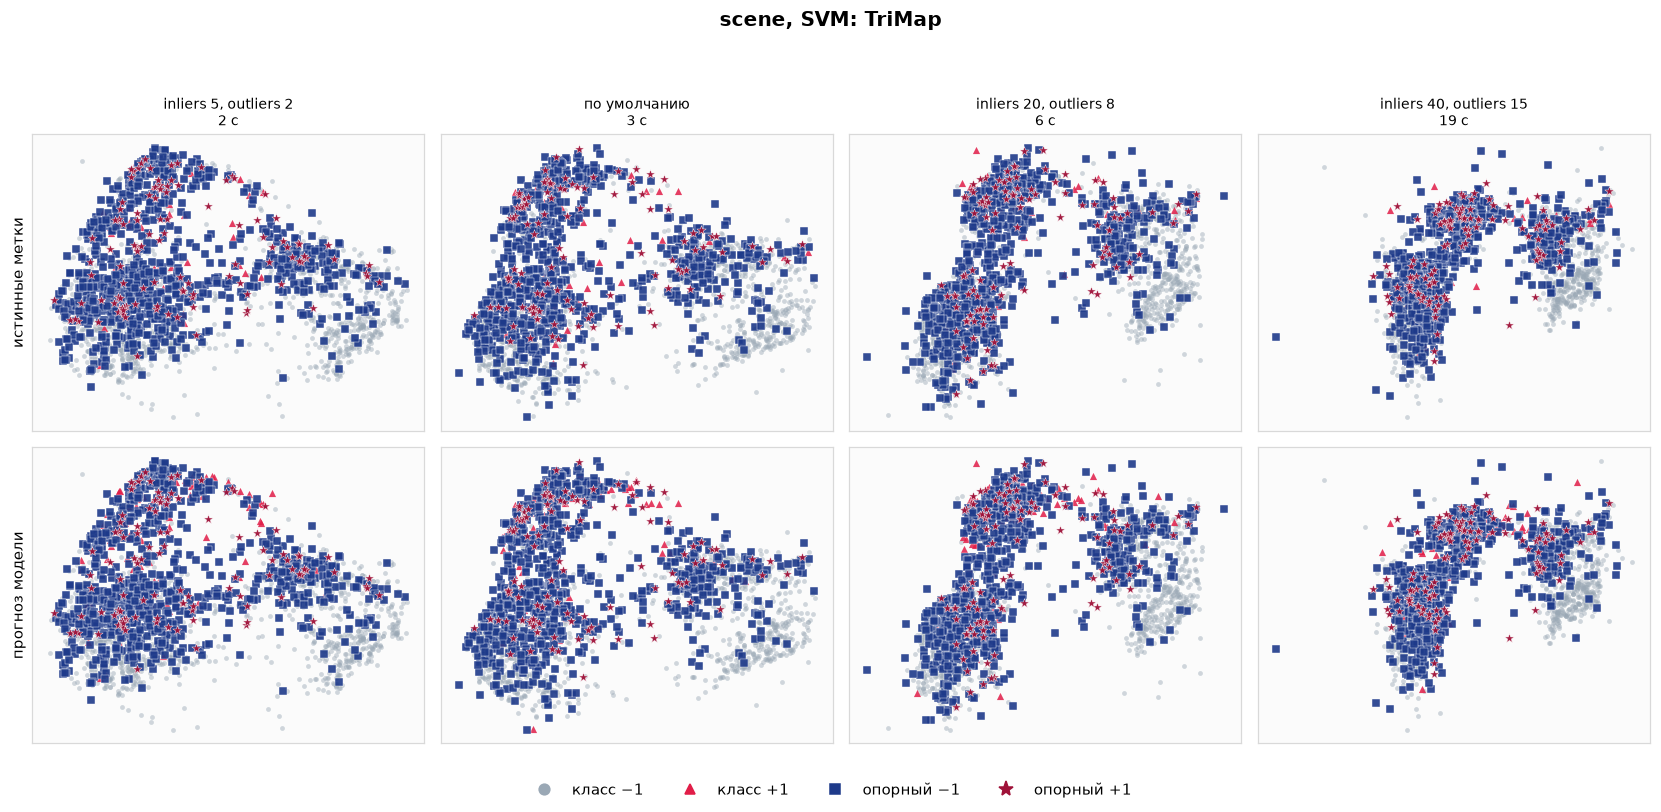

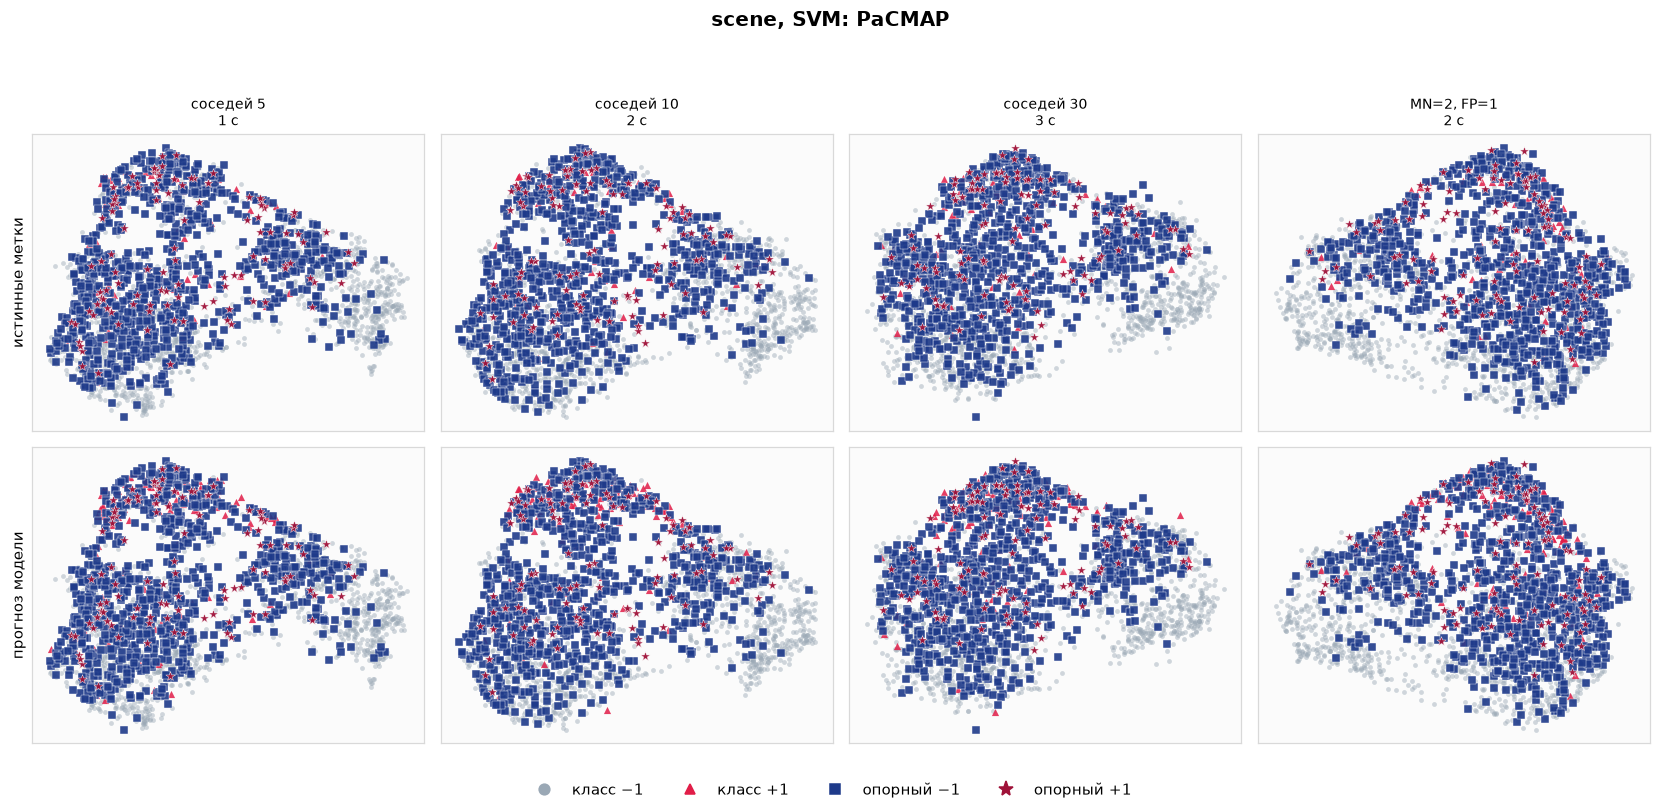

In [ ]:
# Отрисовывваем вложения SVM с разными методами понижения размерности и их разными параметрами
plot_model_embeddings(svm, f"{DATASET_TITLE}, SVM", support=True)

## Часть B. kNN

Сочетаний в сетке: 36, время 3.6 с
Лучшие параметры по F1 на кросс-валидации: {'metric': 'euclidean', 'n_neighbors': 1, 'weights': 'uniform'}
F1 на кросс-валидации: 0.1558
Лучшие 12 сочетаний:


,metric,n_neighbors,weights,mean_test_score,std_test_score
0,euclidean,1,uniform,0.1558,0.0369
1,euclidean,1,distance,0.1558,0.0369
2,cosine,3,distance,0.1486,0.0621
3,cosine,3,uniform,0.1486,0.0621
4,cosine,1,uniform,0.1431,0.0317
5,cosine,1,distance,0.1431,0.0317
6,manhattan,1,distance,0.1381,0.0526
7,manhattan,1,uniform,0.1381,0.0526
8,cosine,5,uniform,0.1192,0.1157
9,cosine,5,distance,0.1192,0.1157


Качество выбранного kNN:


,accuracy,precision (+1),recall (+1),F1 (+1),precision macro,recall macro,F1 macro
выборка,,,,,,,
обучающая,1.000,1.00,1.0000,1.0000,1.0000,1.000,1.0000
тестовая,0.899,0.25,0.1887,0.2151,0.5935,0.572,0.5805


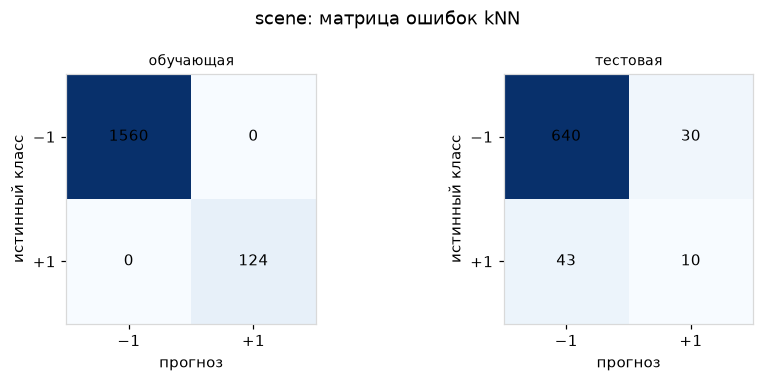

In [ ]:
##Перебираем 3 настройки kNN и выбираем лучшую модель и выводим ее параметры и полученные метрики
knn_grid = {
    "n_neighbors": [1, 3, 5, 9, 15, 31],
    "metric": ["euclidean", "manhattan", "cosine"],
    "weights": ["uniform", "distance"],
}
knn_search = GridSearchCV(
    KNeighborsClassifier(algorithm="brute"),
    knn_grid, scoring=F1_POS, cv=CV, n_jobs=-1, refit=True,
)
started = time.time()
knn_search.fit(X_train_s, y_train)
knn = knn_search.best_estimator_
print(f"Сочетаний в сетке: {len(knn_search.cv_results_['params'])}, время {time.time() - started:.1f} с")
print("Лучшие параметры по F1 на кросс-валидации:", knn_search.best_params_)
print(f"F1 на кросс-валидации: {knn_search.best_score_:.4f}")
print("Лучшие 12 сочетаний:")
display(cv_table(knn_search, 12))
print("Качество выбранного kNN:")
display(metrics_frame(knn, X_train_s, y_train, X_test_s, y_test))
show_confusion(knn, X_train_s, y_train, X_test_s, y_test, f"{DATASET_TITLE}: матрица ошибок kNN")

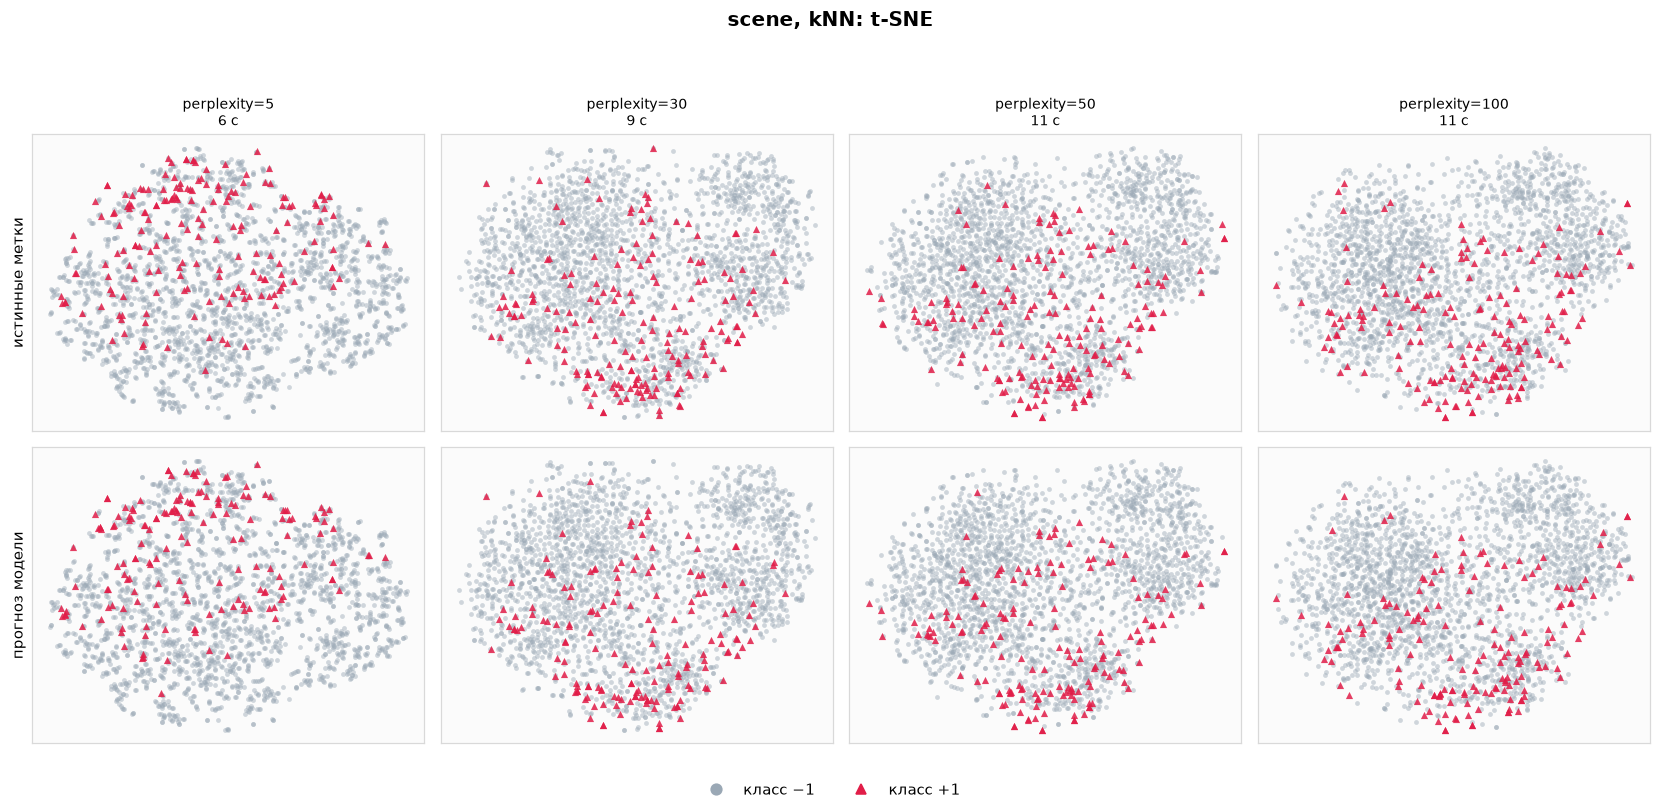

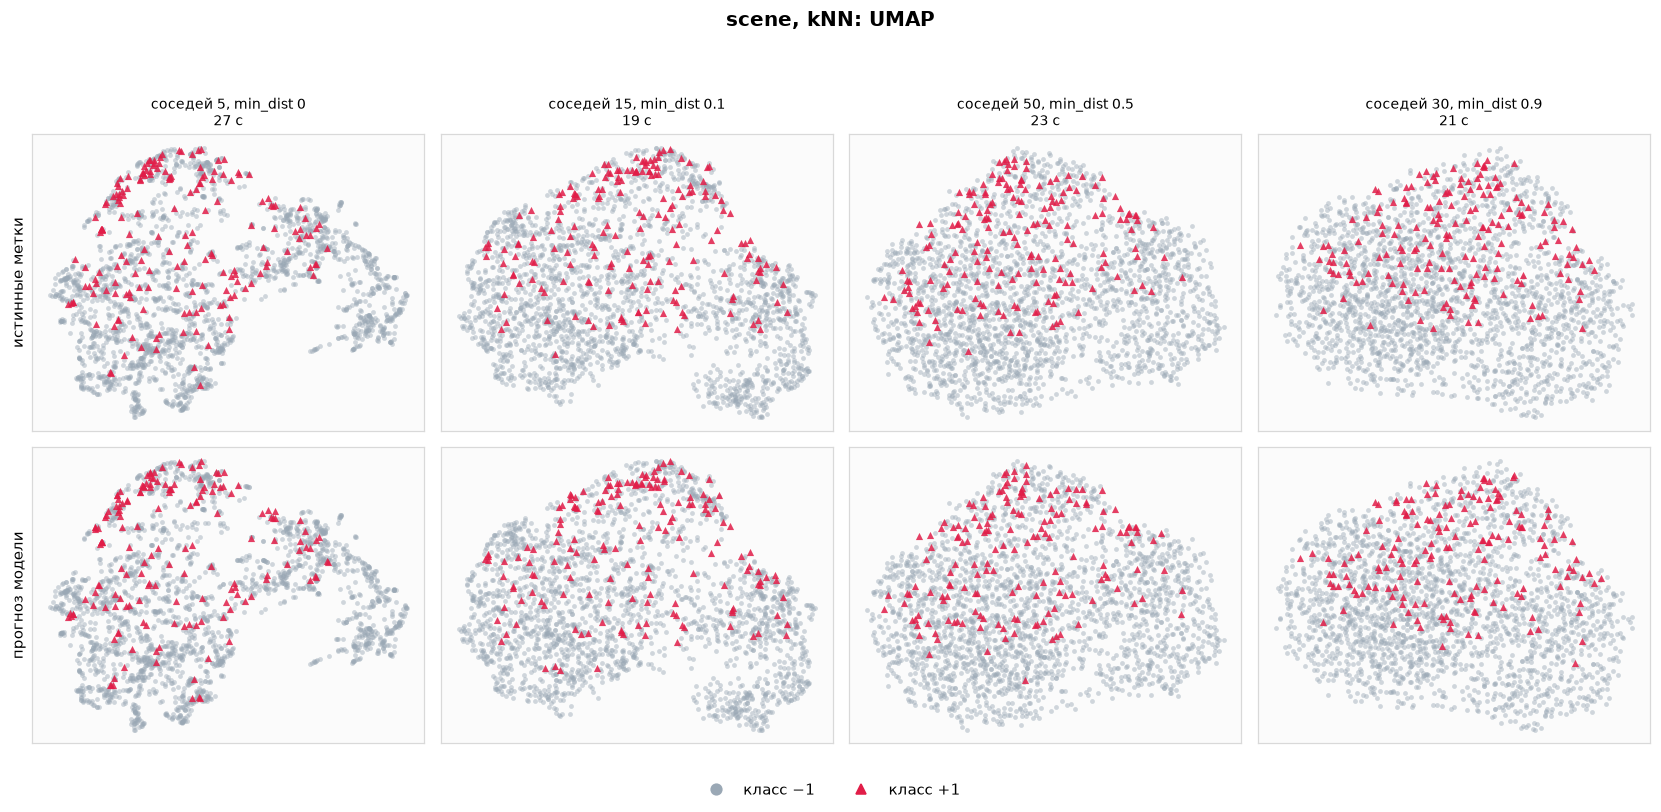

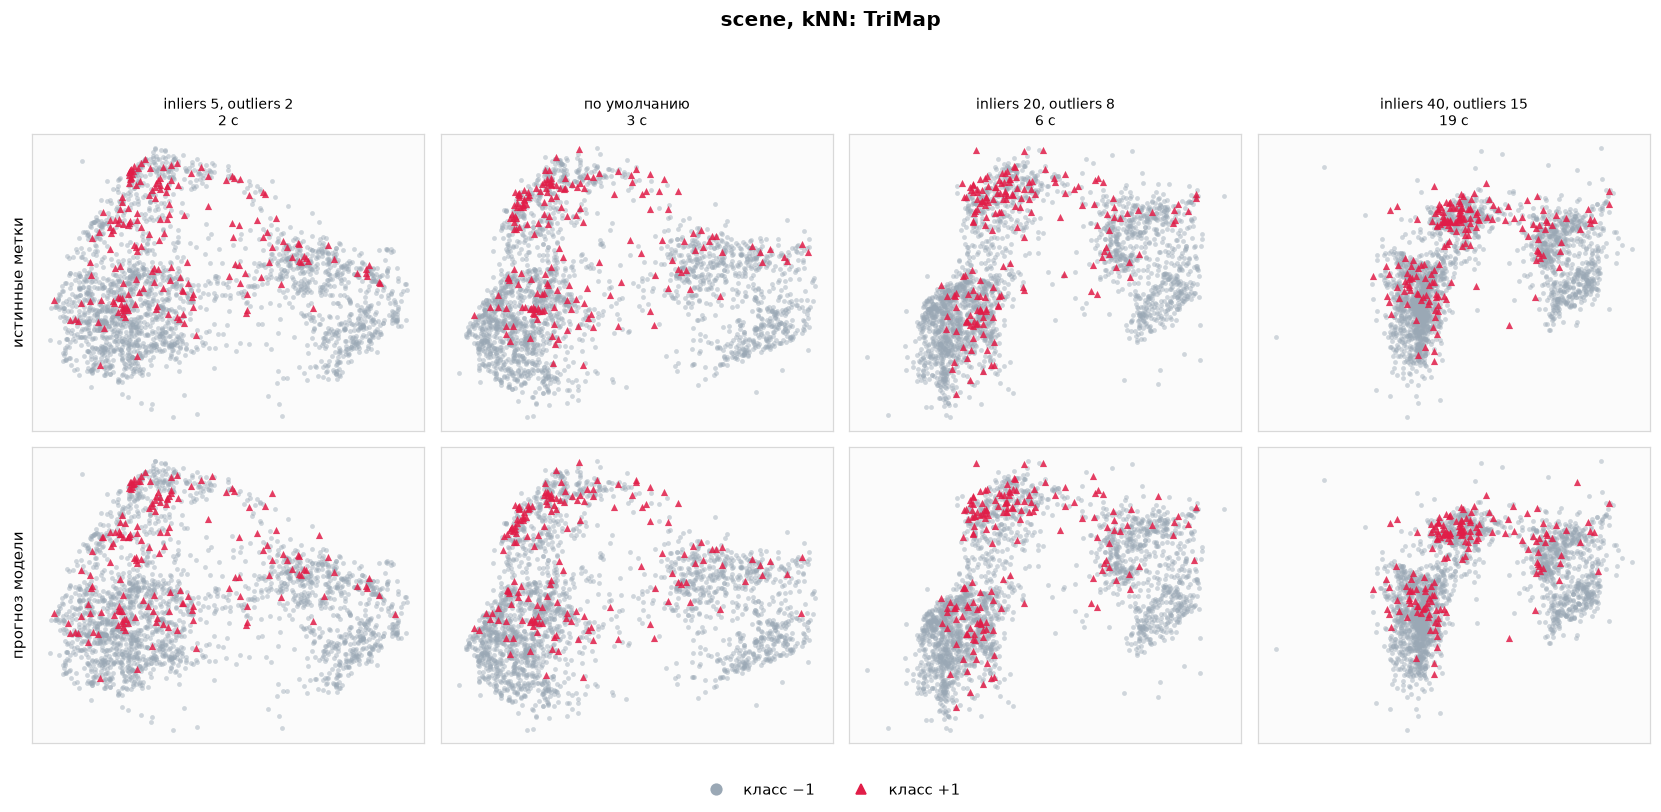

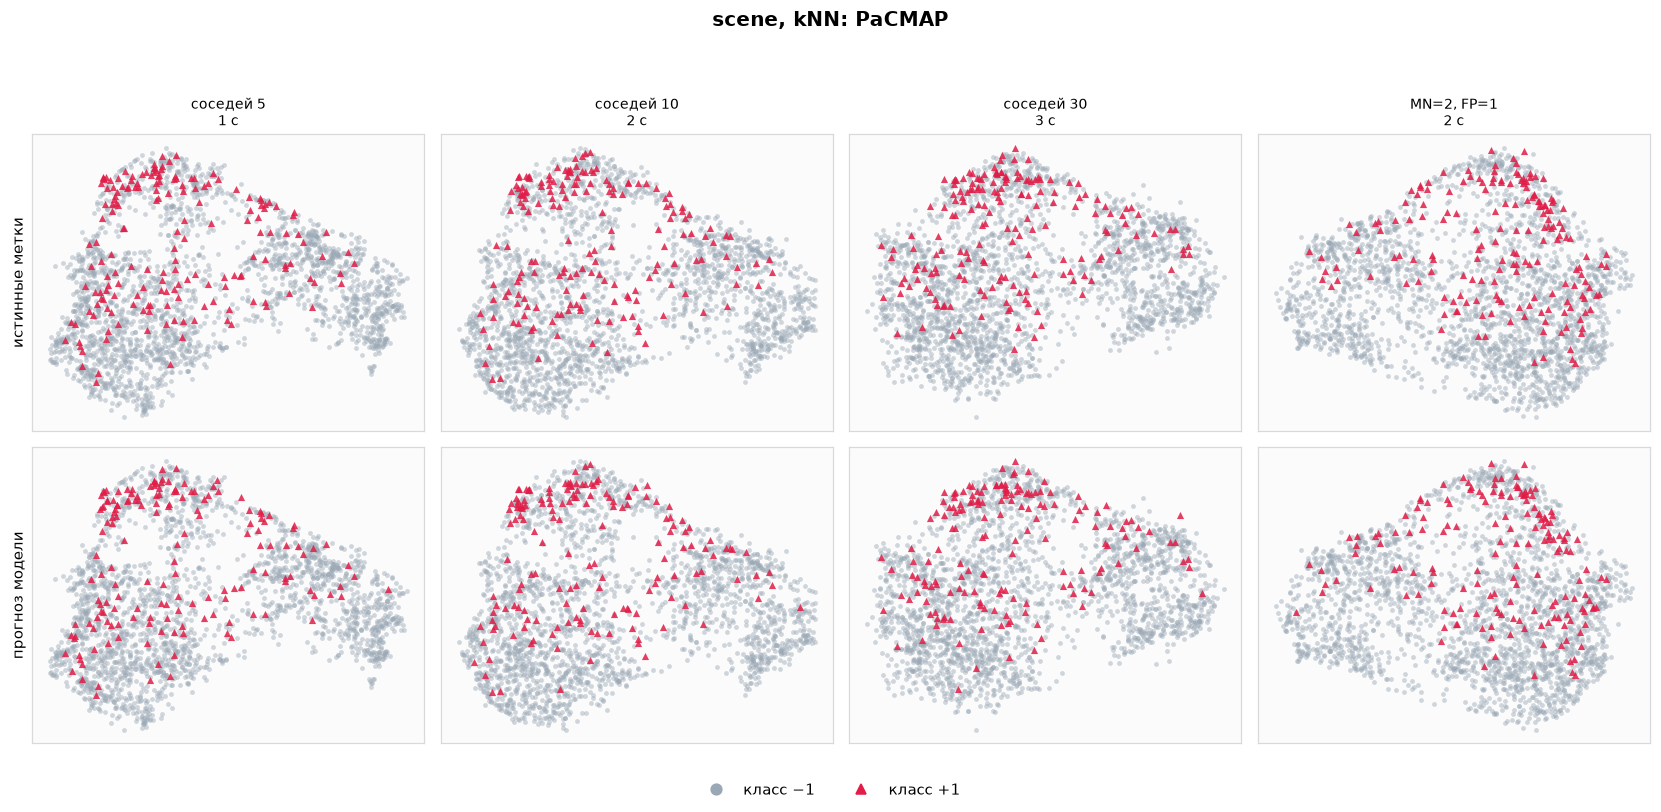

In [ ]:
# Отрисовывваем вложения KNN с разными методами понижения размерности и их разными параметрами
plot_model_embeddings(knn, f"{DATASET_TITLE}, kNN", support=False)

## Часть C. Случайный лес        

In [ ]:
# Перебираем 2 настройки случайного леса и выводим таблицу с результатами 
rows = []
for name, weight in (("без весов классов", None), ("balanced_subsample", "balanced_subsample")):
    clf = RandomForestClassifier(
        n_estimators=100, class_weight=weight, random_state=SEED, n_jobs=-1,
    )
    clf.fit(X_train_s, y_train)
    pred = clf.predict(X_test_s)
    rows.append({
        "модель": name,
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "precision (+1)": round(precision_score(y_test, pred, pos_label=1, zero_division=0), 4),
        "recall (+1)": round(recall_score(y_test, pred, pos_label=1, zero_division=0), 4),
        "F1 (+1)": round(f1_score(y_test, pred, pos_label=1, zero_division=0), 4),
    })
display(pd.DataFrame(rows).set_index("модель"))

,accuracy,precision (+1),recall (+1),F1 (+1)
модель,,,,
без весов классов,0.9295,0.75,0.0566,0.1053
balanced_subsample,0.9308,0.80,0.0755,0.1379


Сочетаний в сетке: 64, время 67.6 с
Лучшие параметры по F1 на кросс-валидации: {'criterion': 'gini', 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 200}
F1 на кросс-валидации: 0.2803
Лучшие 12 сочетаний:


,criterion,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score
0,gini,6,sqrt,4,200,0.2803,0.1395
1,gini,6,sqrt,4,100,0.2771,0.1210
2,entropy,6,log2,4,200,0.2611,0.0991
3,entropy,6,sqrt,1,200,0.2565,0.1065
4,gini,6,sqrt,1,100,0.2563,0.1056
5,entropy,6,sqrt,4,100,0.2481,0.0864
6,entropy,6,sqrt,4,200,0.2478,0.0881
7,entropy,6,log2,4,100,0.2464,0.0855
8,gini,6,log2,4,200,0.2422,0.0906
9,entropy,6,sqrt,1,100,0.2408,0.0770


Качество выбранного случайного леса:


,accuracy,precision (+1),recall (+1),F1 (+1),precision macro,recall macro,F1 macro
выборка,,,,,,,
обучающая,0.9448,0.5728,0.9839,0.7240,0.7857,0.9628,0.8467
тестовая,0.8880,0.2667,0.3019,0.2832,0.6054,0.6181,0.6112


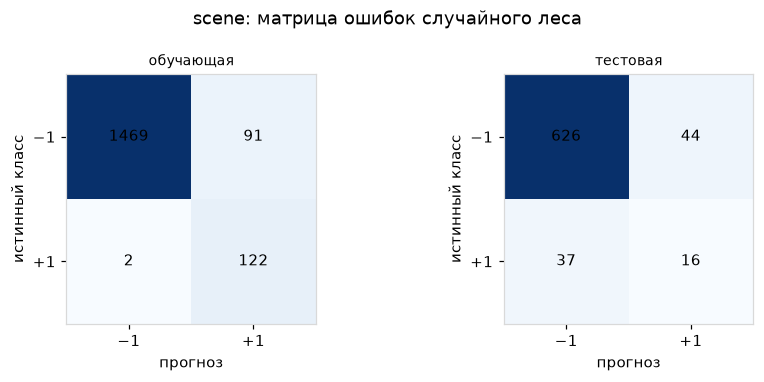

In [ ]:
## Подбираем праметры леса по сетке и оставляем модель с лучшим F1 score редкого класса 
# и выводим ее параметры и полученные метрики и матрицу ошибок
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 6, 12, 24],
    "max_features": ["sqrt", "log2"],
    "min_samples_leaf": [1, 4],
    "criterion": ["gini", "entropy"],
}
rf_search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
    rf_grid, scoring=F1_POS, cv=CV, n_jobs=-1, refit=True,
)
started = time.time()
rf_search.fit(X_train_s, y_train)
rf = rf_search.best_estimator_
print(f"Сочетаний в сетке: {len(rf_search.cv_results_['params'])}, время {time.time() - started:.1f} с")
print("Лучшие параметры по F1 на кросс-валидации:", rf_search.best_params_)
print(f"F1 на кросс-валидации: {rf_search.best_score_:.4f}")
print("Лучшие 12 сочетаний:")
display(cv_table(rf_search, 12))
print("Качество выбранного случайного леса:")
display(metrics_frame(rf, X_train_s, y_train, X_test_s, y_test))
show_confusion(rf, X_train_s, y_train, X_test_s, y_test, f"{DATASET_TITLE}: матрица ошибок случайного леса")

### Два дерева

На рисунке только верхние три уровня, иначе при глубине в десятки узлов лист не прочитать.
Полные числа — глубина, число узлов и листьев — печатаются рядом.

Что лежит в узле:

- признак и порог. Влево уходит объект, у которого признак не больше порога;
- `samples` — сколько объектов этого дерева дошло до узла. Это не вся обучающая выборка, а бутстреп-подвыборка;
- `value` — взвешенные массы классов. Из-за `class_weight` редкий класс тяжелее, поэтому масса +1 больше, чем число таких объектов;
- неоднородность, Джини или энтропия. В листе она меньше, чем в предке, расщепление для этого и выбирается;
- класс листа — тот, у кого масса больше.

Два дерева не обязаны делить по одному и тому же признаку. Каждое видит свою подвыборку с возвращением, а в узле перебирает только случайную горсть признаков.
Важности ниже — среднее уменьшение неоднородности по всему лесу. Это не смысл признака в задаче, а то, как часто лес на него опирался.
        

Дерево 1
узлов 53, глубина 6, листьев 27
корень: x109 ≤ 0.804. Влево идут объекты с признаком не больше порога, вправо — остальные.
в корне объектов 1068, взвешенные массы классов −1 и +1: [0.5, 0.5]
лист с наибольшей долей +1: объектов 5, массы [0.0, 1.0], предсказанный класс 1
лист с наибольшей долей −1: объектов 72, массы [1.0, 0.0], предсказанный класс 0

Дерево 2
узлов 71, глубина 6, листьев 36
корень: x244 ≤ 0.329. Влево идут объекты с признаком не больше порога, вправо — остальные.
в корне объектов 1068, взвешенные массы классов −1 и +1: [0.5, 0.5]
лист с наибольшей долей +1: объектов 4, массы [0.0, 1.0], предсказанный класс 1
лист с наибольшей долей −1: объектов 10, массы [1.0, 0.0], предсказанный класс 0



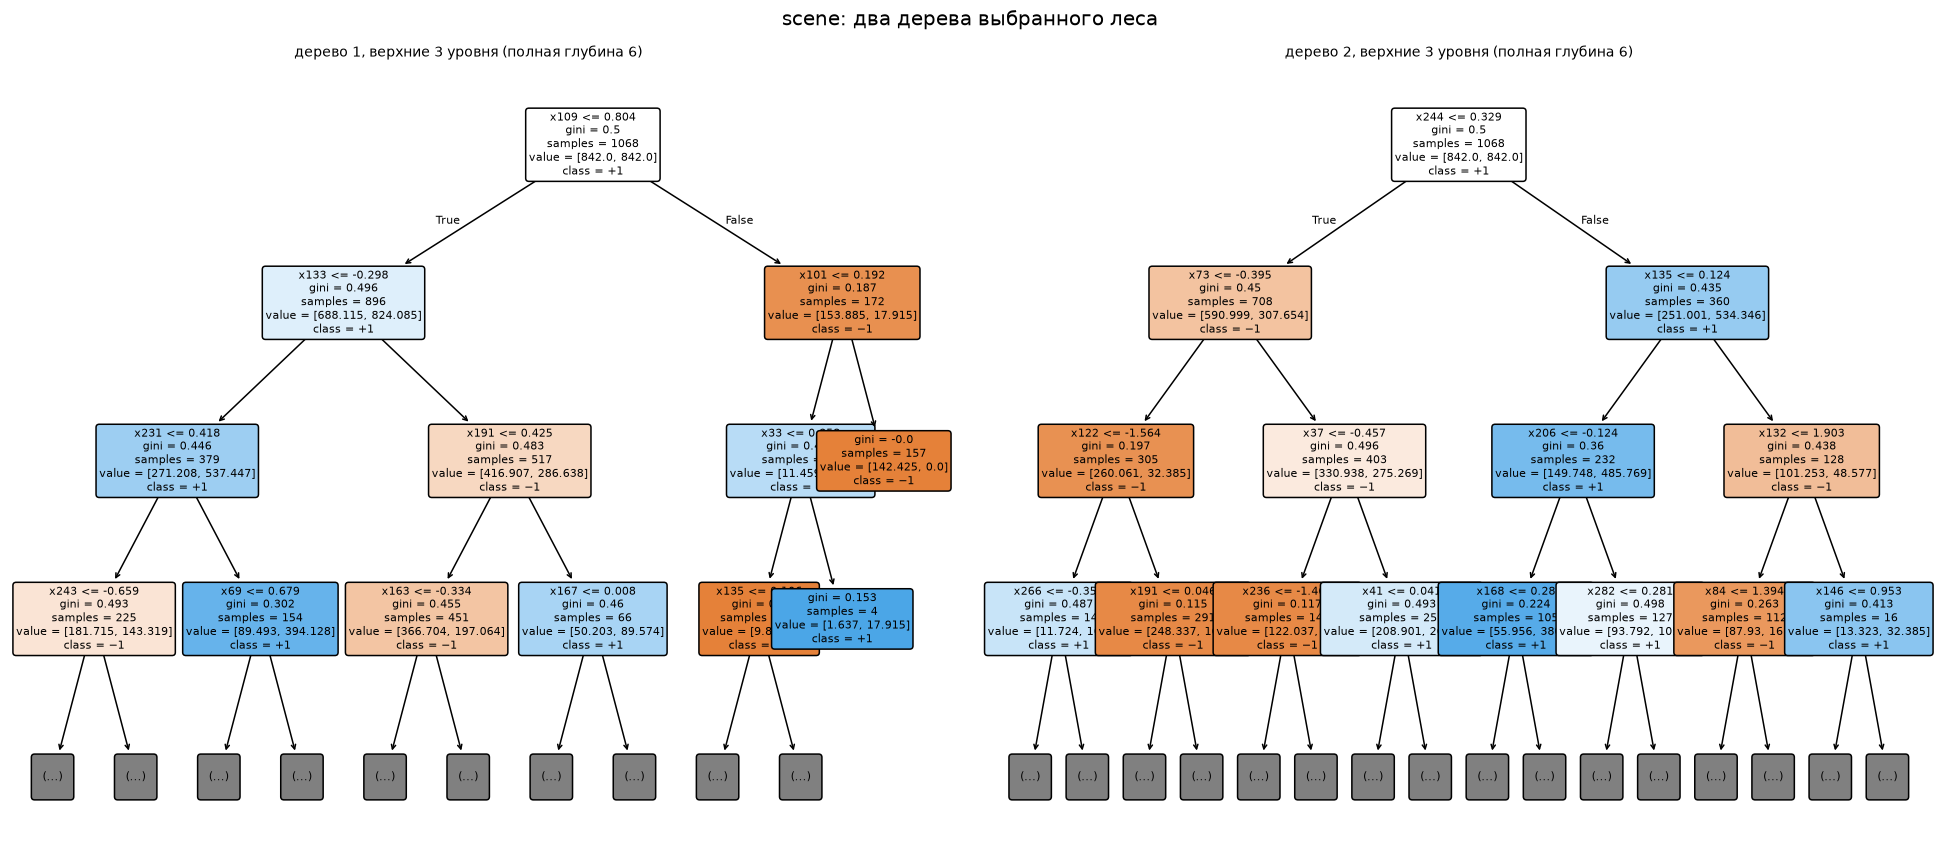

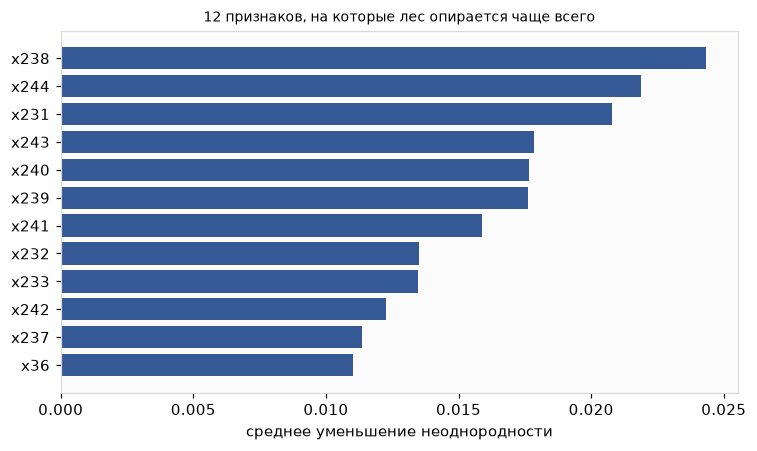

In [ ]:
##Рисуем два дерева из леса верхнеуровнево(3 уровня) 
# и выводим 12 признаков, на которые лес опирается чаще всего
feature_names = [f"x{i}" for i in range(X_train_s.shape[1])]
# Два первых дерева. Они разные: у каждого своя бутстреп-выборка и свой случайный набор признаков в узлах.
trees = [rf.estimators_[0], rf.estimators_[1]]
for i, tree in enumerate(trees, start=1):
    describe_tree(tree, feature_names, f"Дерево {i}")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, tree, name in zip(axes, trees, ("дерево 1", "дерево 2")):
    plot_tree(
        tree, max_depth=3, feature_names=feature_names, class_names=["−1", "+1"],
        filled=True, rounded=True, impurity=True, fontsize=7, ax=ax,
    )
    ax.set_title(f"{name}, верхние 3 уровня (полная глубина {tree.get_depth()})")
fig.suptitle(f"{DATASET_TITLE}: два дерева выбранного леса", fontsize=13)
fig.tight_layout()
plt.show()

importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
top = importances.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color="#345995")
ax.set_xlabel("среднее уменьшение неоднородности")
ax.set_title("12 признаков, на которые лес опирается чаще всего")
fig.tight_layout()
plt.show()

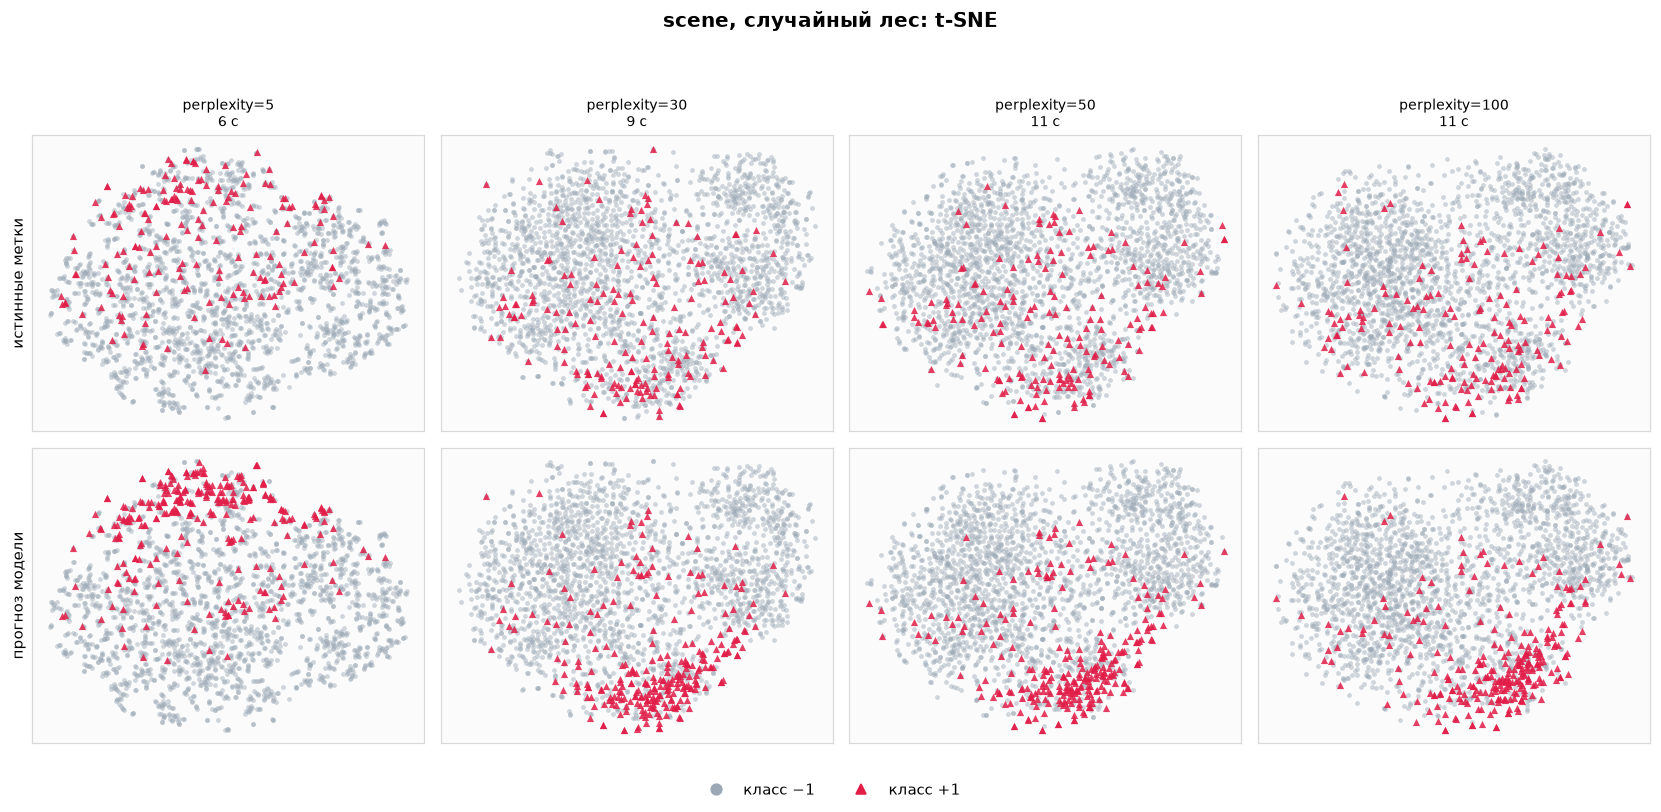

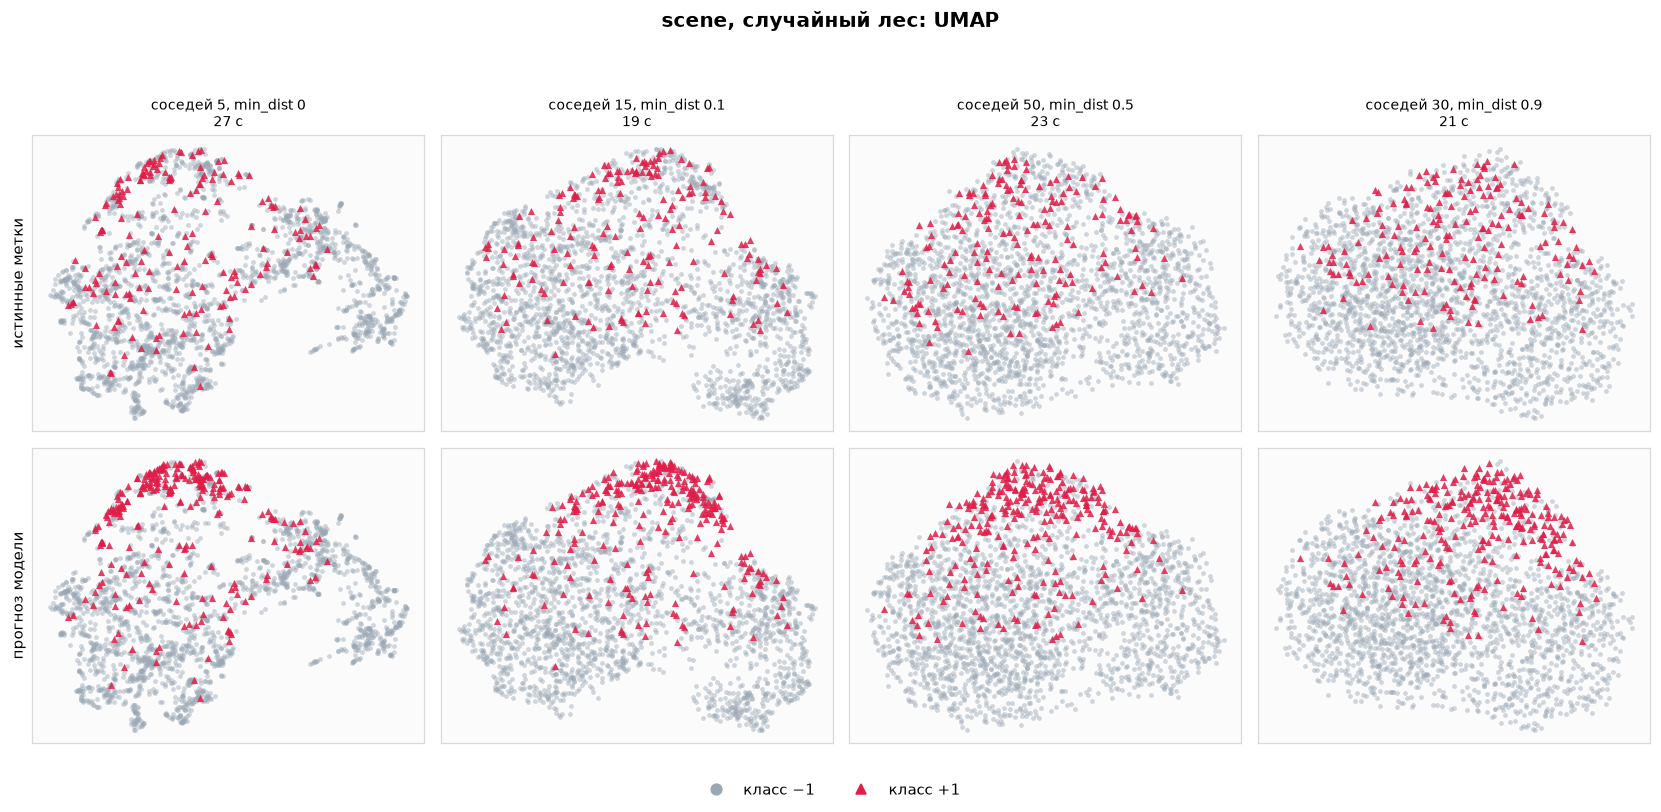

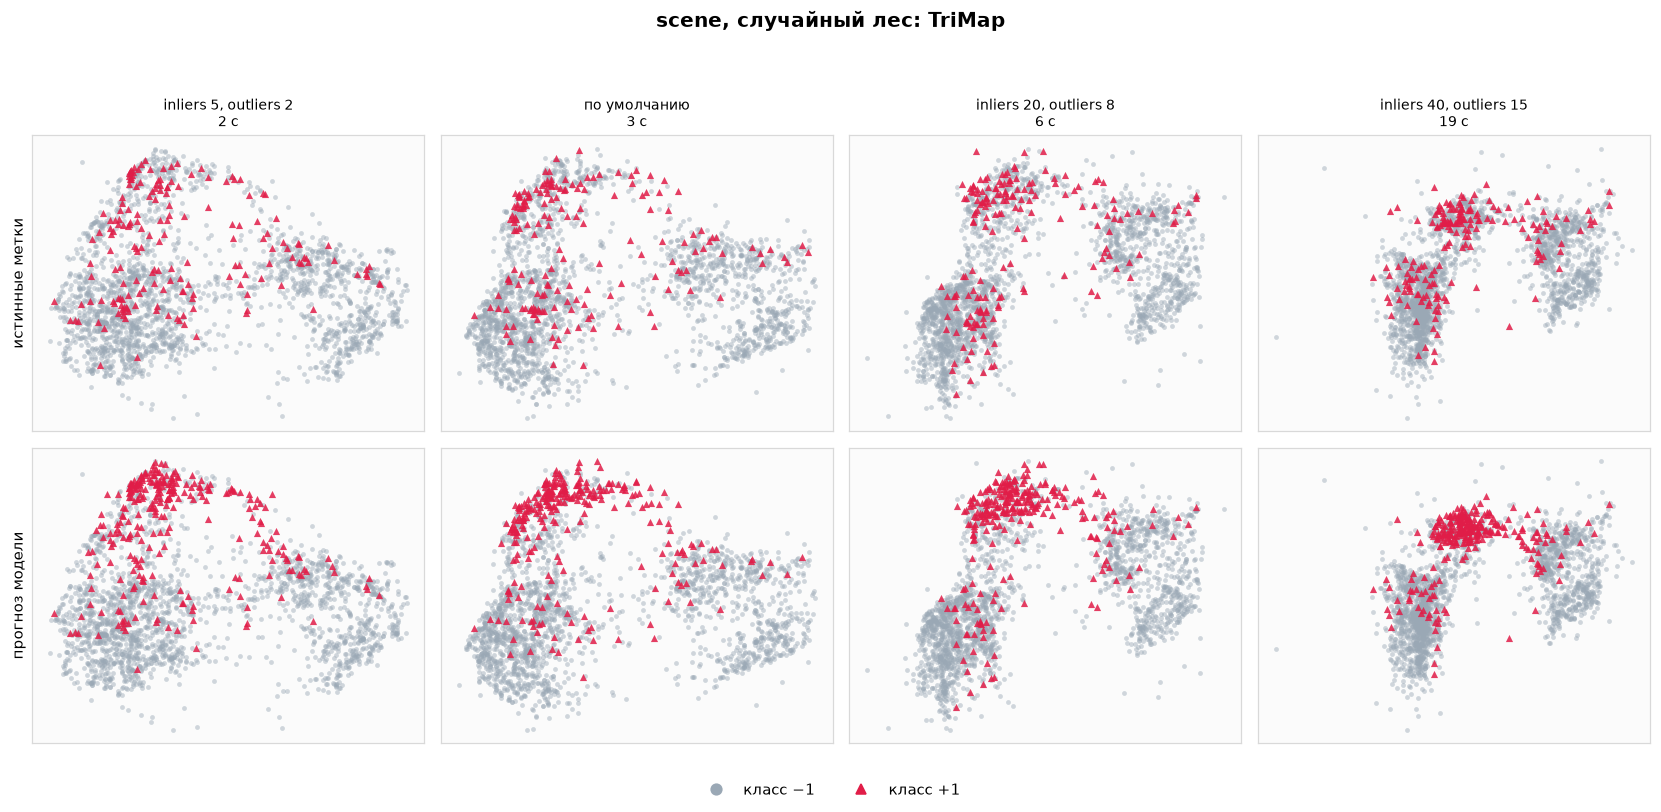

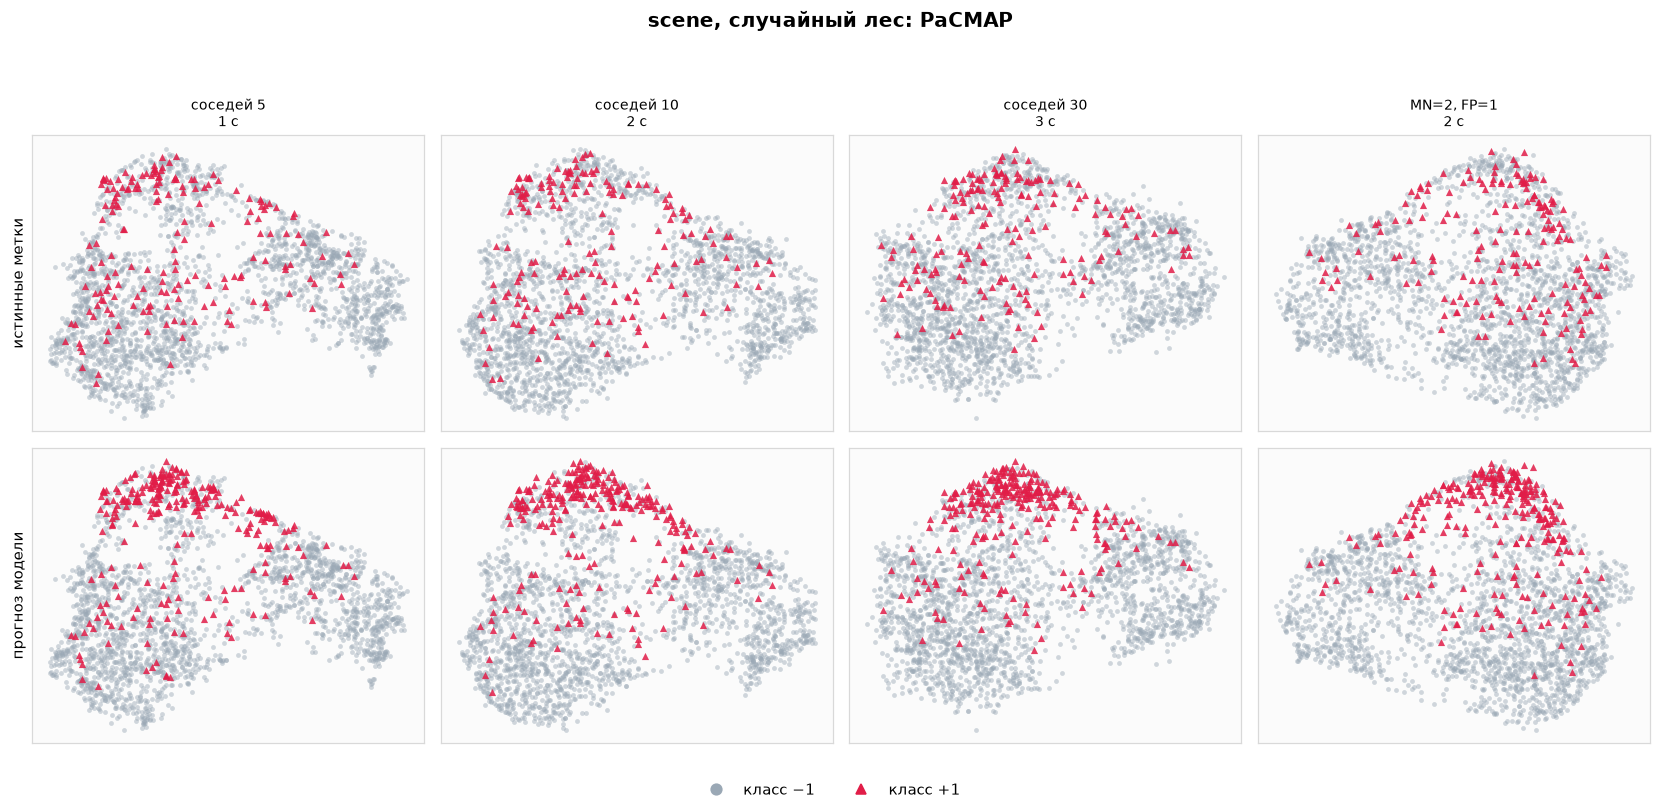

In [ ]:
##Выводим вложения случайного леса с разными методами понижения размерности и их разными параметрами
plot_model_embeddings(rf, f"{DATASET_TITLE}, случайный лес", support=False)

## 6. Сравнение
        

,"accuracy, тест","precision (+1), тест","recall (+1), тест","F1 (+1), тест","F1 (+1), обучение"
модель,,,,,
SVM,0.816,0.1970,0.4906,0.2811,0.5865
kNN,0.899,0.2500,0.1887,0.2151,1.0000
случайный лес,0.888,0.2667,0.3019,0.2832,0.7240


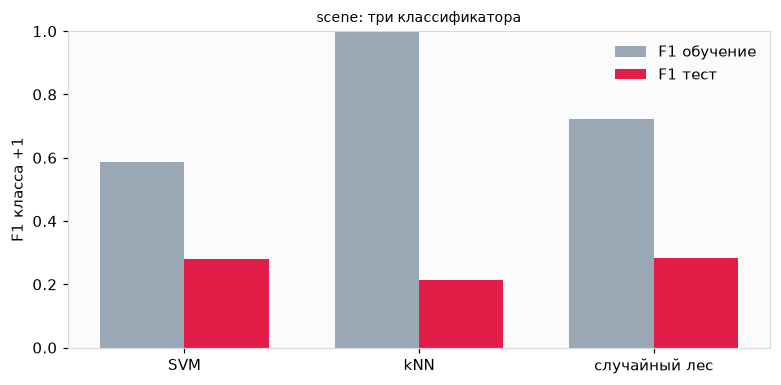

In [ ]:
##Берем лучшие модели каждого вида и выводим их метрики
def scores(model):
    frame = metrics_frame(model, X_train_s, y_train, X_test_s, y_test)
    return frame.loc["обучающая"], frame.loc["тестовая"]

models = {"SVM": svm, "kNN": knn, "случайный лес": rf}
summary_rows = []
for name, model in models.items():
    train_row, test_row = scores(model)
    summary_rows.append({
        "модель": name,
        "accuracy, тест": test_row["accuracy"],
        "precision (+1), тест": test_row["precision (+1)"],
        "recall (+1), тест": test_row["recall (+1)"],
        "F1 (+1), тест": test_row["F1 (+1)"],
        "F1 (+1), обучение": train_row["F1 (+1)"],
    })
summary = pd.DataFrame(summary_rows).set_index("модель")
display(summary)

fig, ax = plt.subplots(figsize=(7.2, 3.6))

x = np.arange(len(summary))
width = 0.36
ax.bar(x - width / 2, summary["F1 (+1), обучение"], width, label="F1 обучение", color="#9aa8b5")
ax.bar(x + width / 2, summary["F1 (+1), тест"], width, label="F1 тест", color="#e11d48")
ax.set_xticks(x, summary.index)
ax.set_ylim(0, 1)
ax.set_ylabel("F1 класса +1")
ax.set_title(f"{DATASET_TITLE}: три классификатора")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
